### 1. Install Hugging Face Transformers
We will need the `transformers` library to load a pre-trained tokenizer compatible with common RAG models (like sentence-transformers or dense passage retrievers).

In [ ]:
!pip install -q transformers

### 2. Define Sample Sentences and Tokenize
Let's define a few sentences representing our knowledge base, load a tokenizer (e.g., `all-MiniLM-L6-v2` which is highly popular for RAG embeddings), and tokenize the sentences.

In [ ]:
from transformers import AutoTokenizer

# 1. Create sample sentences (Knowledge Base / Corpus for RAG)
corpus = [
    "Retrieval-Augmented Generation (RAG) improves LLM responses by fetching relevant documents.",
    "Vector databases store dense vector representations of text passages for fast similarity search.",
    "Tokenization is the process of breaking down text into smaller units called tokens.",
    "Dense retrievers use bi-encoder architectures to embed both queries and documents in the same vector space."
]

# 2. Load a standard pre-trained tokenizer
# 'sentence-transformers/all-MiniLM-L6-v2' is commonly used for generating RAG embeddings
tokenizer = AutoTokenizer.from_pretrained('sentence-transformers/all-MiniLM-L6-v2')

# 3. Tokenize the sentences
# We'll apply padding and truncation to make sure they are of uniform shape for embedding models
tokenized_inputs = tokenizer(
    corpus,
    padding=True,
    truncation=True,
    return_tensors='pt'
)

# Display the results for the first sentence
print("--- Original Sentence ---")
print(corpus[0])

print("\n--- Token IDs (Input IDs) ---")
print(tokenized_inputs['input_ids'][0])

print("\n--- Decoded Tokens ---")
tokens = tokenizer.convert_ids_to_tokens(tokenized_inputs['input_ids'][0])
print(tokens)

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

--- Original Sentence ---
Retrieval-Augmented Generation (RAG) improves LLM responses by fetching relevant documents.

--- Token IDs (Input IDs) ---
tensor([  101, 26384,  1011, 19335,  4245,  1006, 17768,  1007, 24840,  2222,
         2213, 10960,  2011, 18584,  2075,  7882,  5491,  1012,   102,     0,
            0,     0,     0,     0,     0,     0,     0])

--- Decoded Tokens ---
['[CLS]', 'retrieval', '-', 'augmented', 'generation', '(', 'rag', ')', 'improves', 'll', '##m', 'responses', 'by', 'fetch', '##ing', 'relevant', 'documents', '.', '[SEP]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]']


In [ ]:
import pandas as pd

In [ ]:
# Load an actual CSV file instead of an .ipynb file
df = pd.read_csv("/content/sample_data/california_housing_train.csv")

In [ ]:
df

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
0,-114.31,34.19,15.0,5612.0,1283.0,1015.0,472.0,1.4936,66900.0
1,-114.47,34.40,19.0,7650.0,1901.0,1129.0,463.0,1.8200,80100.0
2,-114.56,33.69,17.0,720.0,174.0,333.0,117.0,1.6509,85700.0
3,-114.57,33.64,14.0,1501.0,337.0,515.0,226.0,3.1917,73400.0
4,-114.57,33.57,20.0,1454.0,326.0,624.0,262.0,1.9250,65500.0
...,...,...,...,...,...,...,...,...,...
16995,-124.26,40.58,52.0,2217.0,394.0,907.0,369.0,2.3571,111400.0
16996,-124.27,40.69,36.0,2349.0,528.0,1194.0,465.0,2.5179,79000.0
16997,-124.30,41.84,17.0,2677.0,531.0,1244.0,456.0,3.0313,103600.0
16998,-124.30,41.80,19.0,2672.0,552.0,1298.0,478.0,1.9797,85800.0


### 3. Split the Dataset (80% Train, 20% Test)
Now, we will partition the California Housing dataset we loaded into training and testing subsets using `scikit-learn`.

In [ ]:
from sklearn.model_selection import train_test_split

# Split the dataset into 80% training and 20% testing
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)

# Display the sizes of the resulting datasets
print(f"Total dataset rows: {len(df)}")
print(f"Training set rows (80%): {len(train_df)}")
print(f"Testing set rows (20%): {len(test_df)}")

Total dataset rows: 17000
Training set rows (80%): 13600
Testing set rows (20%): 3400


### 4. Visualize Housing Median Age Distribution with a Pie Chart
Let's categorize the `housing_median_age` into three groups: 'New' (<= 15 years), 'Moderate' (16-35 years), and 'Old' (> 35 years), and plot their proportion using a pie chart.

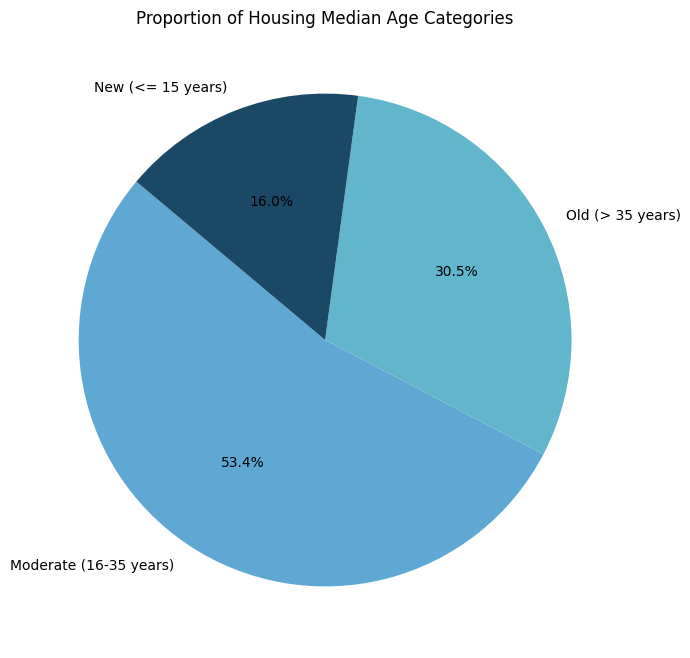

In [ ]:
import matplotlib.pyplot as plt

# Define the bins and labels for categorizing the housing median age
bins = [0, 15, 35, float('inf')]
labels = ['New (<= 15 years)', 'Moderate (16-35 years)', 'Old (> 35 years)']

# Categorize the data
age_categories = pd.cut(df['housing_median_age'], bins=bins, labels=labels)
counts = age_categories.value_counts()

# Plot the pie chart
plt.figure(figsize=(8, 8))
plt.pie(
    counts,
    labels=counts.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=['#5fa8d3', '#62b6cb', '#1b4965']
)
plt.title('Proportion of Housing Median Age Categories')
plt.show()

### 5. Train and Test a Machine Learning Model
We will use a Linear Regression model to predict `median_house_value`. First, we will prepare our features ($X$) and target ($y$) from the training and testing sets, train the model, and then evaluate its performance on the test partition.

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# Define features and target variable
features = ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income']
target = 'median_house_value'

# Prepare training sets
X_train = train_df[features]
y_train = train_df[target]

# Prepare testing sets
X_test = test_df[features]
y_test = test_df[target]

# Initialize and train the model
model = LinearRegression()
model.fit(X_train, y_train)

# Make predictions on the test dataset
y_pred = model.predict(X_test)

# Evaluate model performance
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("--- Model Evaluation Results on Test Data ---")
print(f"Root Mean Squared Error (RMSE): ${rmse:,.2f}")
print(f"R-squared (R2) Score: {r2:.4f}")

--- Model Evaluation Results on Test Data ---
Root Mean Squared Error (RMSE): $68,078.33
R-squared (R2) Score: 0.6636


### 6. Test the Model with Your Own Custom Data
Input your own custom parameters in the dictionary below to see what median house value the model predicts.

In [ ]:
import pandas as pd

# Define custom input parameters for the features used in the model
custom_data = {
    'longitude': [-118.25],          # Longitude of location
    'latitude': [34.05],             # Latitude of location
    'housing_median_age': [25.0],    # Median age of houses in block
    'total_rooms': [2000.0],         # Total number of rooms
    'total_bedrooms': [450.0],       # Total number of bedrooms
    'population': [1200.0],          # Population of the block
    'households': [400.0],           # Total households
    'median_income': [4.5]           # Median household income (in tens of thousands)
}

# Convert to a DataFrame
custom_df = pd.DataFrame(custom_data)

# Use the trained model to predict
predicted_value = model.predict(custom_df)[0]

print("--- Custom Prediction Result ---")
print(f"Predicted Median House Value: ${predicted_value:,.2f}")

--- Custom Prediction Result ---
Predicted Median House Value: $237,664.71
